In [1]:
from bikeroot import BikeNetwork, hmls_solve, alg_utils, NGAMOBRPProblem, linastar_solve, eval_utils, namoa_solve

In [2]:
location = "Spokane, WA"
loc_name = location.split(",")[0].lower().replace(" ", "_")
criteria = ['travel distance', 'travel time', 'safety', 'comfort']
G = BikeNetwork(location)
# G.load_graph(f'data/small_maps/{loc_name}_1000_withcost.graphml')
G.load_graph(f'data/testing_maps/{loc_name}_20000_withcost.graphml')
G.weights_to_floats(criteria)
print(f"Loaded graph for {location} with {len(G.graph.nodes)} nodes and {len(G.graph.edges)} edges.")

Loaded graph for Spokane, WA with 104451 nodes and 288279 edges.


In [3]:
# G.prints('nodes', 100)

In [4]:
src= '48925897'
dst= '50968572'

In [5]:
# paths_costs = linastar_solve(G.graph, src, dst, criteria, sol_count=50, find_all_sols = True, log_level='info')

criteria = ['travel distance', 'safety']

In [6]:
paths_costs = namoa_solve(G.graph, src, dst, criteria, H='tc', debug=False)

In [7]:
# paths_costs_norm = namoa_solve(G.graph, src, dst, criteria, H=None, debug=False, )

In [8]:
# print(len(paths_costs_norm))#by meters


In [9]:
print(len(paths_costs))
print(paths_costs[0])

31
(['48925897', '11017100072', '11017100063', '11017100062', '11017107308', '10705436458', '10705443011', '10705436459', '10705436460', '10705436467', '364160125', '10705436465', '12234377342', '12234377344', '11017107348', '11017107341', '11017107345', '11017107342', '4418582620', '11018804107', '4418582602', '1528815638', '1528815637', '9380413493', '7835328680', '7835328694', '7835328676', '4465147422', '11539228604', '4465147405', '10558515216', '10558589555', '7007187833', '7007187832', '7007184238', '11166123296', '11166123305', '10276708887', '11166123301', '10276718421', '10154935912', '51030894', '10154935913', '8563071421', '10154935920', '10154935927', '10154936053', '10154936051', '10154935935', '10154935936', '10154936066', '10154936069', '50968572'], {'travel distance': 1349.0568848135438, 'safety': 2804.5571425805006})


In [10]:
paths, costs = eval_utils.paths_costs_split(paths_costs)
nd_paths,nd_costs = eval_utils.remove_dominated_solutions(criteria, paths, costs)

In [11]:
print(len(nd_paths), len(nd_costs))

31 31


In [ ]:
# paths_costs_lin = linastar_solve(G.graph, src, dst, criteria, sol_count=15, find_all_sols = True)
# print(len(paths_costs_lin))
# print(paths_costs_lin[0])

UnboundLocalError: cannot access local variable 'pref' where it is not associated with a value

<Axes: title={'center': 'Distance vs Safety Pareto Optimal Set\n for a route in Spokane, WA'}, xlabel='Travel distance (m)', ylabel='Safety cost (lower = safer)'>

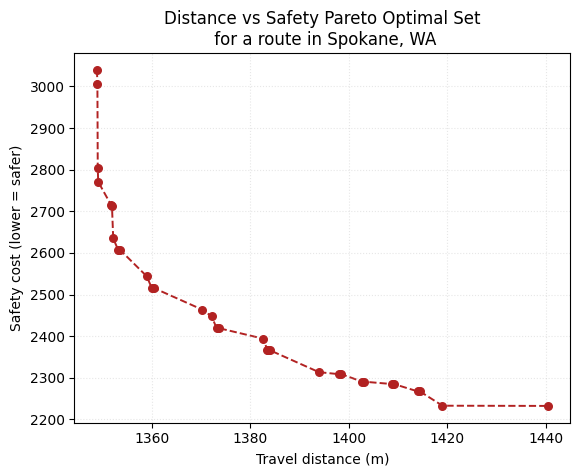

In [20]:
import matplotlib.pyplot as plt
import numpy as np

def plot_distance_safety(results, *, ax=None,
                         point_kwargs=None, line_kwargs=None,
                         annotate=False):
    """
    Scatter every (distance, safety) pair and connect them with a line.

    Parameters
    ----------
    results : Sequence[dict]
        Each entry must contain 'travel distance' and 'safety'.
    ax : matplotlib.axes.Axes, optional
        Existing axes to draw on. If ``None`` a new figure/axes is created.
    point_kwargs, line_kwargs : dict, optional
        Extra styling options for the scatter and connecting line.
    annotate : bool, default False
        Write index labels next to each point.
    """
    # ---- 0.  Styling defaults ---------------------------------------------
    point_kwargs = point_kwargs or dict(color="firebrick", s=30, zorder=2)
    line_kwargs  = line_kwargs  or dict(color="firebrick", linewidth=1.4,
                                        linestyle="--", zorder=1)

    # ---- 1.  Collect points ------------------------------------------------
    pts = np.array([(d["travel distance"], d["safety"]) for d in results])
    if pts.size == 0:
        raise ValueError("`results` is empty or lacks the expected keys.")

    # ---- 2.  Sort for a clean line (distance ascending) -------------------
    order = np.argsort(pts[:, 0])
    pts_sorted = pts[order]

    # ---- 3.  Plot ----------------------------------------------------------
    if ax is None:
        _, ax = plt.subplots()

    ax.scatter(pts_sorted[:, 0], pts_sorted[:, 1], **point_kwargs)
    ax.plot(pts_sorted[:, 0], pts_sorted[:, 1], **line_kwargs)

    ax.set_xlabel("Travel distance (m)")
    ax.set_ylabel("Safety cost (lower = safer)")
    ax.set_title("Distance vs Safety Pareto Optimal Set\n for a route in Spokane, WA")
    ax.grid(True, alpha=0.3, linestyle=":")

    if annotate:
        for i, (x, y) in enumerate(pts_sorted):
            ax.text(x, y, str(order[i]), fontsize=8,
                    ha="right", va="bottom")

    return ax



plot_distance_safety(costs)